# Shaping ablations

One figure comparing the shaping ablations, for sharing (for example with supervisors). Every reward gives each response credit for a code block (`correct_format`) and for code that parses (`passes_syntax_check`), the *shaping* terms, and up to a fixed amount of *library credit* for reusing a library. The ablations change only the shaping weights. GRPO normalises the rewards within each prompt's group of rollouts, so what training sees is the **shaping ratio**: each shaping weight divided by the library credit. The main runs give 0.25 / 0.25 / 1.5 (format / syntax / library), a ratio of 0.17.

- **(a) library use and (b) pass@1 against the shaping ratio**, on LibReuseBench's test split at the final epoch (4), with a 95% bootstrap interval over tasks. Two import runs give library credit 1.0 rather than 1.5 (hollow markers): they come from the first ablation design and are compared by their ratio. With no shaping (ratio 0), the scale of the library credit doesn't matter.
- **One row per reward**: the share of training rollouts that use a library (smoothed, per optimizer step, on an epoch axis), next to the share of LibReuseBench test responses that use one at each epoch's checkpoint (the base model at 0). The less shaping, the lighter the line; the main run is drawn thicker.

Library use here counts any third-party library that is imported and called, for every reward (including target, whose reward only pays for target libraries).

In [1]:
"""Compare the shaping ablations: how the format and syntax weights change library use."""

import json
import os
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from llm_cgr import load_jsonl
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

from src.utils.config import load_model_settings
from src.utils.paths import baseline_dir, model_output_dir


# run from the repo root (the folder holding .git), so the relative paths src uses
# (config/, output/) resolve - its results are in output/04_shaping_ablation/
REPO_ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / ".git").exists()
)
os.chdir(REPO_ROOT)

# each reward's runs, from least to most shaping. their weights are read from each run's
# own record (grpo/train_results.json), not repeated here
RUNS = {
    "import": [
        "qwen3-8b-9185",  # lu-import-s0
        "qwen3-8b-f2ca",  # lu-import-matched (main)
        "qwen3-8b-4db4",  # lu-import-s25
        "qwen3-8b-584b",  # lu-import, the iteration 03 weights
    ],
    "usage": [
        "qwen3-8b-a342",  # lu-usage-s0
        "qwen3-8b-3079",  # lu-usage (main)
        "qwen3-8b-caf3",  # lu-usage-s50
    ],
    "target": [
        "qwen3-8b-6626",  # lu-target-s0
        "qwen3-8b-f57b",  # lu-target (main)
        "qwen3-8b-255a",  # lu-target-s50
    ],
}
# each reward's main run: 0.25 / 0.25 shaping and 1.5 library credit
MAIN_RUNS = {
    "import": "qwen3-8b-f2ca",
    "usage": "qwen3-8b-3079",
    "target": "qwen3-8b-f57b",
}

# the base model, and which eval results to read - files are named
# "{dataset}-{profile}-{prompt_style}.json"
BASE_MODEL = "qwen3-8b"
BENCHMARK = "libreusebench_test"
DECODING_PROFILE = "default_16k"
PROMPT_STYLE = "base"

# the epoch every run is compared at - the last, fixed before the runs were trained
FINAL_EPOCH = 4

# resamples of the tasks for each 95% interval
BOOTSTRAP_SAMPLES = 10_000

# steps averaged into each point of the smoothed training curves
SMOOTHING_WINDOW = 7

# where the figure is saved - the ablations' iteration folder
FIGURE_FILE = Path("output/04_shaping_ablation/figures/shaping_ablations.png")

In [2]:
# chart colours and style, as in grpo_training_summary.ipynb
INK = "#52514e"  # text
SURFACE = "#fcfcfb"  # chart background
RULE = "#c3c2b7"  # axes and reference lines
BASE_COLOUR = "#8a8984"  # the base model, a neutral grey

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": RULE,
        "axes.labelcolor": INK,
        "axes.titlesize": 10,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "xtick.color": RULE,
        "ytick.color": RULE,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "font.size": 9,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "lines.linewidth": 2,
    }
)

# each reward's colour, the same as in the paper figures (notebooks/paper_figures.ipynb)
REWARD_COLOURS = {
    "import": "#eb6834",  # orange
    "usage": "#1155b9",  # blue
    "target": "#a25ddc",  # purple
}

# within a reward, each shaping ratio is a shade of the reward's hue: the less shaping, the
# lighter. one hue and monotone lightness per reward, checked with a palette validator
# against the chart background
SHADES = {
    "import": {0.0: "#fe8e65", 0.17: "#e05e29", 0.25: "#c84704", 0.5: "#842c01"},
    "usage": {0.0: "#81b2ff", 0.17: "#4789f2", 0.33: "#2264c9"},
    "target": {0.0: "#cb94ff", 0.17: "#aa66e5", 0.33: "#863fbd"},
}

## 1. The runs

Each run's folder comes from the registry entry of its epoch 1 checkpoint (`config/trained_models.yaml`), so the notebook still works after the runs move into an iteration folder. The training curves are what TRL logged at every optimizer step (`grpo/trainer_state.json`), and the benchmark results are each epoch's eval (`epoch{n}/`), with the base model's at epoch 0.

In [3]:
def eval_file(
    folder: Path,
    suffix: str = ".json",
) -> Path:
    """
    The benchmark's results file in an eval folder (".json" for the summary,
    ".generations.jsonl" for the per-response records).

    Returns the file path.
    """
    return folder / f"{BENCHMARK}-{DECODING_PROFILE}-{PROMPT_STYLE}{suffix}"


def task_rates(
    folder: Path,
    field: str,
) -> pd.Series:
    """
    The share of each task's responses that meet a per-response field, such as "passed" or
    "external_lib_used".

    Returns the rates, indexed by task id.
    """
    records = pd.DataFrame(
        load_jsonl(
            file_path=str(eval_file(folder=folder, suffix=".generations.jsonl"))
        ),
    )
    return records.groupby("task_id")[field].mean()


def bootstrap_interval(
    rates: pd.Series,
) -> tuple[float, float]:
    """
    A 95% interval for the mean rate over tasks, from resampling the tasks with replacement.

    Returns the interval's lower and upper ends.
    """
    rng = np.random.default_rng(seed=0)
    values = rates.to_numpy(dtype=float)
    resamples = rng.integers(0, len(values), size=(BOOTSTRAP_SAMPLES, len(values)))
    means = values[resamples].mean(axis=1)
    low, high = np.percentile(means, [2.5, 97.5])
    return float(low), float(high)


def final_epoch_rows(
    folder: Path,
) -> list[dict]:
    """
    Library use and pass@1 on the benchmark for one eval folder, each with its interval.

    Returns one row per metric.
    """
    rows = []
    for metric, field in [("library use", "external_lib_used"), ("pass@1", "passed")]:
        rates = task_rates(folder=folder, field=field)
        low, high = bootstrap_interval(rates=rates)
        rows.append({"metric": metric, "value": rates.mean(), "low": low, "high": high})
    return rows


BASE_DIR = baseline_dir(model=BASE_MODEL)
base_values = {row["metric"]: row["value"] for row in final_epoch_rows(folder=BASE_DIR)}

run_info: dict[str, dict] = {}  # each run's reward, weights and shaping ratio
training_curves: dict[str, pd.Series] = {}  # library use in training rollouts, by epoch
benchmark_curves: dict[str, pd.Series] = {}  # library use on the benchmark, by epoch
summary_rows = []  # library use and pass@1 at the final epoch
for reward, run_ids in RUNS.items():
    for run_id in run_ids:
        # find the run's folder from its registry entry
        settings = load_model_settings(model_key=f"{run_id}-epoch1")
        run_dir = model_output_dir(
            model_key=f"{run_id}-epoch1",
            model_settings=settings,
        ).parent

        # the reward's weights: the two shaping terms, and the library credit (the most the
        # library components can add together)
        train_results = json.loads(
            (run_dir / "grpo" / "train_results.json").read_text()
        )
        weights = train_results["reward_profile"]["weights"]
        shaping = weights["correct_format"]
        assert weights["passes_syntax_check"] == shaping, f"{run_id}: uneven shaping"
        library_credit = sum(weights.values()) - 2 * shaping
        ratio = round(shaping / library_credit, 2)
        run_info[run_id] = {
            "reward": reward,
            "profile": train_results["reward_profile"]["name"],
            "shaping": shaping,
            "library credit": library_credit,
            "ratio": ratio,
            "main": run_id == MAIN_RUNS[reward],
            "label": (
                f"{shaping:g} / {shaping:g} / {library_credit:.1f}, ratio {ratio:g}"
                + (" (main)" if run_id == MAIN_RUNS[reward] else "")
            ),
        }

        # library use in the training rollouts, logged as a 0-1 rate at every step, smoothed
        # and placed on an epoch axis
        state = json.loads((run_dir / "grpo" / "trainer_state.json").read_text())
        steps = pd.DataFrame(
            [entry for entry in state["log_history"] if "loss" in entry],
        ).set_index("step")
        steps_per_epoch = state["max_steps"] / state["num_train_epochs"]
        uses = steps["rewards/external_lib_used/mean"]
        smoothed = uses.rolling(SMOOTHING_WINDOW, center=True, min_periods=1).mean()
        training_curves[run_id] = smoothed.set_axis(uses.index / steps_per_epoch)

        # library use on the benchmark at each epoch's checkpoint, the base model at 0
        folders = {
            0: BASE_DIR,
            **{epoch: run_dir / f"epoch{epoch}" for epoch in range(1, FINAL_EPOCH + 1)},
        }
        benchmark_curves[run_id] = pd.Series(
            {
                epoch: json.loads(eval_file(folder=folder).read_text())["analysis"][
                    "library_use"
                ]["used"]["per_response"]["using_lib_rate"]
                for epoch, folder in folders.items()
            }
        )

        # the final epoch's library use and pass@1, with their intervals
        for row in final_epoch_rows(folder=run_dir / f"epoch{FINAL_EPOCH}"):
            summary_rows.append({"run": run_id, **run_info[run_id], **row})

summary_df = pd.DataFrame(summary_rows)
display(
    summary_df.pivot_table(
        index=["reward", "ratio", "profile", "run"],
        columns="metric",
        values=["value", "low", "high"],
        sort=False,
    ).style.format("{:.1%}")
)
print(
    f"base model: {base_values['library use']:.1%} library use, {base_values['pass@1']:.1%} pass@1"
)

base model: 15.7% library use, 75.5% pass@1


## 2. The figure

Drawn from the tables above, and saved as `output/04_shaping_ablation/figures/shaping_ablations.png`. The same panels are also saved as four figures of two, one per row, for slides: `shaping_ablations_1_overview.png`, `_2_import.png`, `_3_usage.png` and `_4_target.png` in the same folder.

saved: output/04_shaping_ablation/figures/shaping_ablations.png


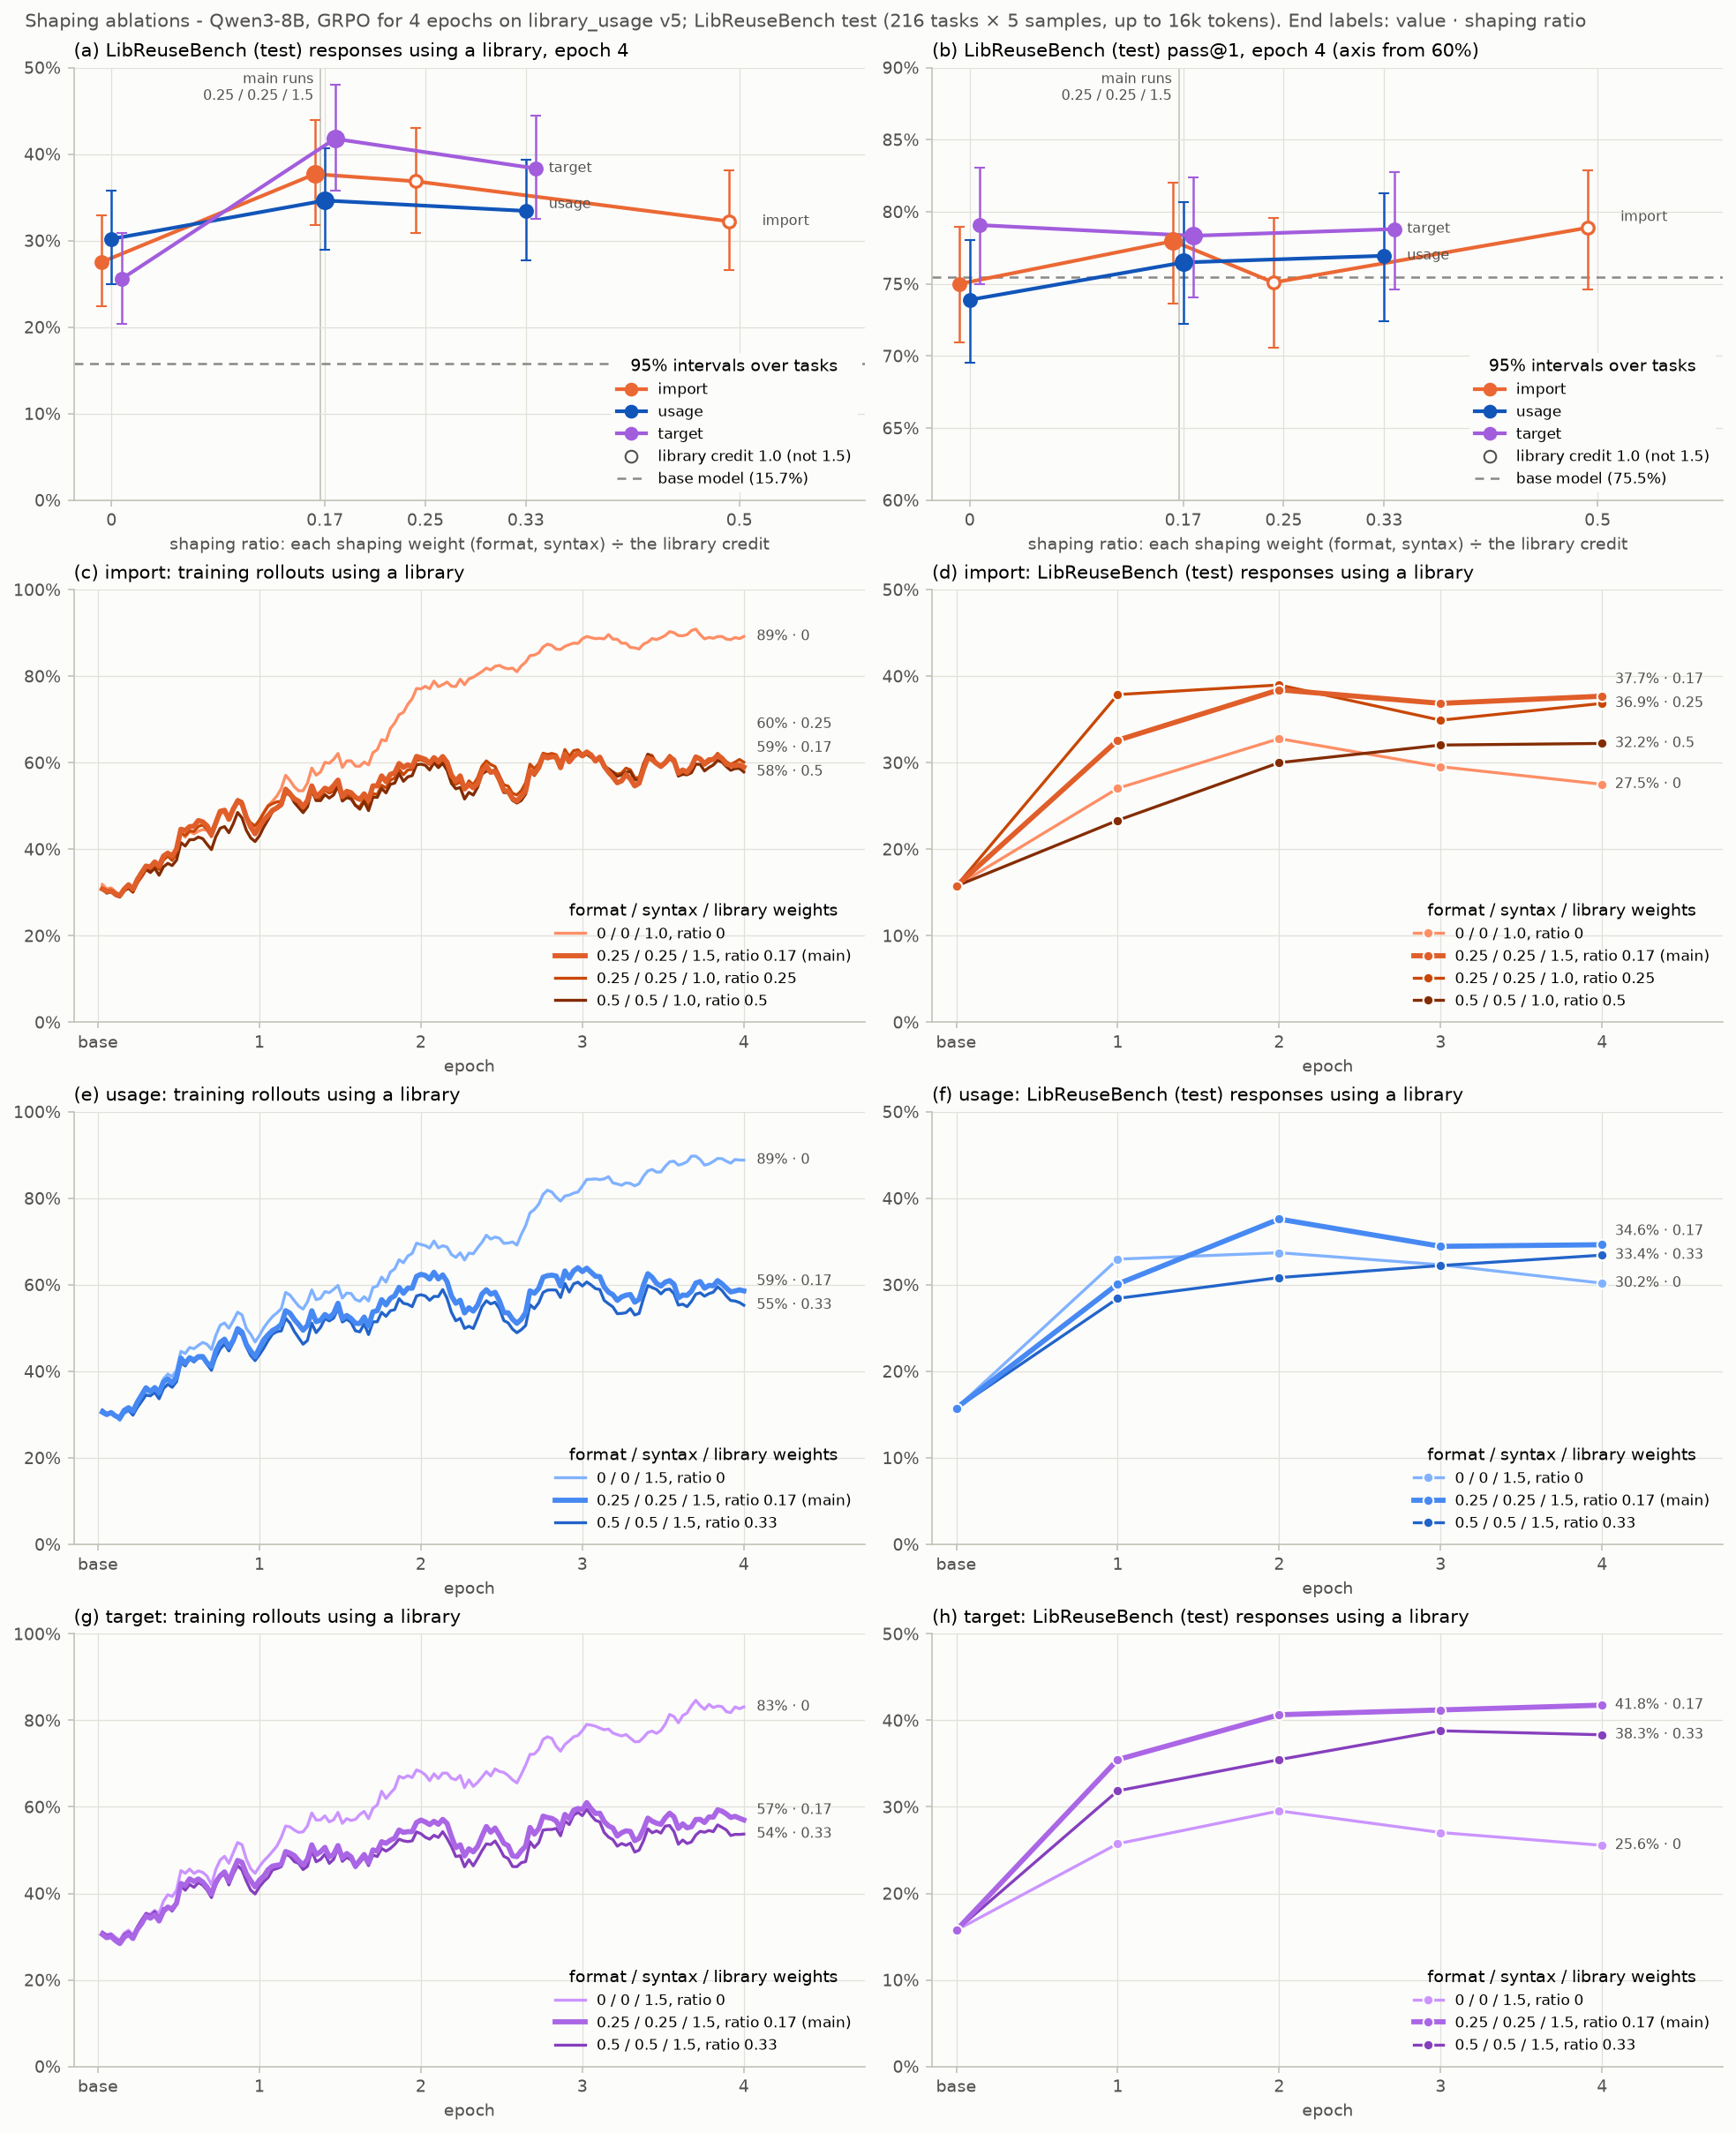

saved: output/04_shaping_ablation/figures/shaping_ablations_1_overview.png


saved: output/04_shaping_ablation/figures/shaping_ablations_2_import.png


saved: output/04_shaping_ablation/figures/shaping_ablations_3_usage.png


saved: output/04_shaping_ablation/figures/shaping_ablations_4_target.png


In [4]:
def percent_axis(
    ax: Axes,
) -> None:
    """Label an axis's y values (rates from 0 to 1) as percentages."""
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0%}"))


def label_ends(
    ax: Axes,
    ends: list[tuple[float, float, str]],
) -> None:
    """
    Write a label just right of where each line ends, given as (x, y, text), nudged apart so
    that lines ending close together don't print on top of each other.
    """
    low, high = ax.get_ylim()
    min_gap = 0.055 * (high - low)
    last_y = -np.inf
    for x, y, text in sorted(ends, key=lambda end: end[1]):
        last_y = max(y, last_y + min_gap)
        ax.annotate(
            text,
            xy=(x, last_y),
            xytext=(7, 0),
            textcoords="offset points",
            va="center",
            color=INK,
            fontsize=7.5,
        )


# how far each reward's points are shifted along the ratio axis in (a) and (b)
DODGE = {"import": -0.008, "usage": 0.0, "target": 0.008}


def plot_against_ratio(
    ax: Axes,
    metric: str,
) -> None:
    """
    Plot one final-epoch metric against the shaping ratio, one line per reward, with each
    point's 95% interval. A hollow marker is a run whose library credit is 1.0 rather than
    1.5 (only the ratio matters to training, but the scale differs from the main runs).
    """
    base = base_values[metric]
    ax.axhline(base, color=BASE_COLOUR, linewidth=1.2, linestyle=(0, (4, 3)), zorder=1)
    for reward in RUNS:
        colour = REWARD_COLOURS[reward]
        points = summary_df[
            (summary_df["reward"] == reward) & (summary_df["metric"] == metric)
        ].sort_values("ratio")
        # rewards that share a ratio sit side by side, so their intervals don't overlap
        points = points.assign(x=points["ratio"] + DODGE[reward])
        ax.plot(points["x"], points["value"], color=colour, zorder=2)
        ax.errorbar(
            points["x"],
            points["value"],
            yerr=[points["value"] - points["low"], points["high"] - points["value"]],
            fmt="none",
            ecolor=colour,
            elinewidth=1.2,
            capsize=3,
            zorder=2,
        )
        for _, point in points.iterrows():
            # with no shaping the library credit's scale doesn't matter, so only runs with
            # shaping and a credit other than 1.5 are hollow
            same_scale = point["shaping"] == 0 or point["library credit"] == 1.5
            ax.plot(
                point["x"],
                point["value"],
                marker="o",
                markersize=8.5 if point["main"] else 6.5,
                markerfacecolor=colour if same_scale else SURFACE,
                markeredgecolor=colour,
                markeredgewidth=1.6,
                linestyle="none",
                zorder=3,
            )
    # each line named where it ends
    label_ends(
        ax=ax,
        ends=[
            (
                points["ratio"].iloc[-1] + max(DODGE.values()),
                points["value"].iloc[-1],
                reward,
            )
            for reward in RUNS
            for points in [
                summary_df[
                    (summary_df["reward"] == reward) & (summary_df["metric"] == metric)
                ].sort_values("ratio")
            ]
        ],
    )
    # the main runs' ratio, shared by all three rewards
    ax.axvline(1 / 6, color=RULE, linewidth=0.8, zorder=0)
    ax.annotate(
        "main runs\n0.25 / 0.25 / 1.5",
        xy=(1 / 6, 1),
        xycoords=("data", "axes fraction"),
        xytext=(-4, -2),
        textcoords="offset points",
        ha="right",
        va="top",
        color=INK,
        fontsize=7.5,
    )
    ratios = sorted({info["ratio"] for info in run_info.values()})
    ax.set_xticks(ratios, labels=[f"{ratio:g}" for ratio in ratios])
    ax.set_xlim(-0.03, 0.6)
    ax.set_xlabel(
        "shaping ratio: each shaping weight (format, syntax) ÷ the library credit"
    )
    percent_axis(ax)


def draw_overview(
    library_ax: Axes,
    pass_ax: Axes,
) -> None:
    """
    Draw panels (a) and (b): the final epoch's library use and pass@1 against the shaping
    ratio, each with its legend.
    """
    plot_against_ratio(ax=library_ax, metric="library use")
    library_ax.set_ylim(0, 0.5)
    library_ax.set_title(
        f"(a) LibReuseBench (test) responses using a library, epoch {FINAL_EPOCH}",
    )
    plot_against_ratio(ax=pass_ax, metric="pass@1")
    pass_ax.set_ylim(0.6, 0.9)
    pass_ax.set_title(
        f"(b) LibReuseBench (test) pass@1, epoch {FINAL_EPOCH} (axis from 60%)",
    )
    overview_legend = [
        *[
            Line2D([], [], color=colour, marker="o", markersize=6.5, label=reward)
            for reward, colour in REWARD_COLOURS.items()
        ],
        Line2D(
            [],
            [],
            color=INK,
            marker="o",
            markersize=6.5,
            markerfacecolor=SURFACE,
            linestyle="none",
            label="library credit 1.0 (not 1.5)",
        ),
    ]
    for ax, metric in [(library_ax, "library use"), (pass_ax, "pass@1")]:
        base_line = Line2D(
            [],
            [],
            color=BASE_COLOUR,
            linewidth=1.2,
            linestyle=(0, (4, 3)),
            label=f"base model ({base_values[metric]:.1%})",
        )
        ax.legend(
            handles=[*overview_legend, base_line],
            loc="lower right",
            title="95% intervals over tasks",
            frameon=True,
            facecolor=SURFACE,
            edgecolor="none",
            framealpha=1,
        )


def draw_reward(
    reward: str,
    train_ax: Axes,
    bench_ax: Axes,
    letters: str,
) -> None:
    """
    Draw one reward's pair of panels, lettered with the two letters given: library use in
    the training rollouts, next to library use on the benchmark at each epoch.
    """
    train_ends, bench_ends = [], []
    for run_id in RUNS[reward]:
        info = run_info[run_id]
        line_style: dict[str, Any] = {
            "color": SHADES[reward][info["ratio"]],
            "linewidth": 2.8 if info["main"] else 1.6,
            "label": info["label"],
            "zorder": 3 if info["main"] else 2,
        }
        training = training_curves[run_id]
        train_ax.plot(training.index, training, **line_style)
        train_ends.append(
            (
                training.index[-1],
                training.iloc[-1],
                f"{training.iloc[-1]:.0%} · {info['ratio']:g}",
            ),
        )
        benchmark = benchmark_curves[run_id]
        bench_ax.plot(
            benchmark.index,
            benchmark,
            marker="o",
            markersize=5.5,
            markeredgecolor=SURFACE,
            **line_style,
        )
        bench_ends.append(
            (
                FINAL_EPOCH,
                benchmark.loc[FINAL_EPOCH],
                f"{benchmark.loc[FINAL_EPOCH]:.1%} · {info['ratio']:g}",
            ),
        )
    train_ax.set_ylim(0, 1)
    train_ax.set_title(
        f"({letters[0]}) {reward}: training rollouts using a library",
    )
    bench_ax.set_ylim(0, 0.5)
    bench_ax.set_title(
        f"({letters[1]}) {reward}: LibReuseBench (test) responses using a library",
    )
    label_ends(ax=train_ax, ends=train_ends)
    label_ends(ax=bench_ax, ends=bench_ends)
    for ax in [train_ax, bench_ax]:
        ax.set_xticks(
            range(FINAL_EPOCH + 1),
            labels=["base", *map(str, range(1, FINAL_EPOCH + 1))],
        )
        ax.set_xlim(-0.15, FINAL_EPOCH + 0.75)  # room on the right for end labels
        ax.set_xlabel("epoch")
        percent_axis(ax)
        ax.legend(loc="lower right", title="format / syntax / library weights")


def save_with_header(
    fig: Figure,
    file: Path,
) -> None:
    """Add the header line that every version of the figure shares, then save it."""
    fig.suptitle(
        "Shaping ablations - Qwen3-8B, GRPO for 4 epochs on library_usage v5; "
        "LibReuseBench test (216 tasks × 5 samples, up to 16k tokens). "
        "End labels: value · shaping ratio",
        x=0.01,
        ha="left",
        color=INK,
        fontsize=10,
    )
    file.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(file, dpi=200, bbox_inches="tight")
    print(f"saved: {file}")


# the letters of each reward's pair of panels, the same in every version of the figure
REWARD_LETTERS = {"import": "cd", "usage": "ef", "target": "gh"}

# the full figure: the overview on top, then one row per reward
fig, axes = plt.subplots(
    4,
    2,
    figsize=(13, 16),
    dpi=150,
    layout="constrained",
)
draw_overview(library_ax=axes[0, 0], pass_ax=axes[0, 1])
for row, reward in enumerate(RUNS, start=1):
    draw_reward(
        reward=reward,
        train_ax=axes[row, 0],
        bench_ax=axes[row, 1],
        letters=REWARD_LETTERS[reward],
    )
save_with_header(fig=fig, file=FIGURE_FILE)
plt.show()

# the same panels as four figures of two (one row each), for slides - numbered in the
# order they appear in the full figure
for number, part in enumerate(["overview", *RUNS], start=1):
    fig, (left_ax, right_ax) = plt.subplots(
        1,
        2,
        figsize=(13, 4),
        dpi=150,
        layout="constrained",
    )
    if part == "overview":
        draw_overview(library_ax=left_ax, pass_ax=right_ax)
    else:
        draw_reward(
            reward=part,
            train_ax=left_ax,
            bench_ax=right_ax,
            letters=REWARD_LETTERS[part],
        )
    save_with_header(
        fig=fig,
        file=FIGURE_FILE.with_name(f"{FIGURE_FILE.stem}_{number}_{part}.png"),
    )
    plt.close(fig)